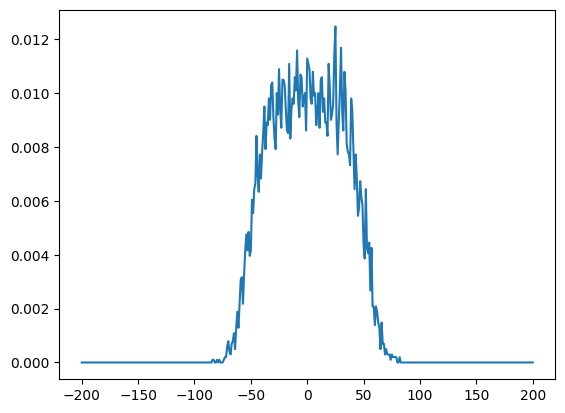

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate

#Oppgave a
runs = 100
n = 101
t_steps = 200
h = 1
dt = 1
beta_k = 1
n_runs = 100

k = 1
V_case = "i"  # "i" eller "ii"

x_min = -200
x_max = 200
x_vals = np.arange(x_min, x_max + 1, dtype=int)


def V(x):
    if V_case == "i":
        return k
    elif V_case == "ii":
        return -k*x


def probability(x0):
    vm = V(x0-1)
    v0 = V(x0)
    vp = V(x0+1)
    p_p = 1 / (1 + np.exp(-beta_k * (vm - vp)) + np.exp(-beta_k * (v0 - vp)))
    p0  = 1 / (1 + np.exp(-beta_k * (vm - v0)) + np.exp(-beta_k * (vp - v0)))
    p_m = 1 / (1 + np.exp(-beta_k * (vp - vm)) + np.exp(-beta_k * (v0 - vm)))
    return p_p, p0, p_m

all_positions = []
for i in range(runs):
    positions = np.arange(n, dtype=int) - n//2
    for t in range(t_steps):
        new_positions = positions.copy()
        for j in range(n):
            x0 = positions[j]
            p_p, p0, p_m = probability(x0)

            number = np.random.uniform(0, 1)
            
            if number <= p_m:
                new_positions[j] = x0 - 1
            elif number >= 1 - p_p:
                new_positions[j] = x0 + 1
        positions = new_positions
    all_positions.append(positions.copy())

all_positions = np.array(all_positions)
vals, counts = np.unique(all_positions.flatten(), return_counts=True)

count_map = dict(zip(vals, counts))
counts_on_xvals = np.array([count_map.get(x, 0) for x in x_vals], dtype=float)

distribution = counts_on_xvals / (runs * n)

plt.plot(x_vals, distribution)
plt.show()


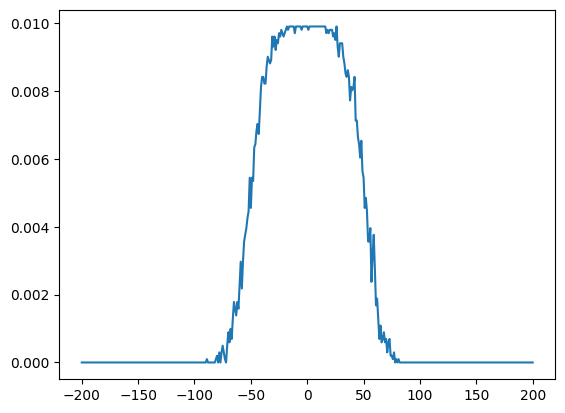

In [9]:
#Oppgave b
all_positions = []
for i in range(runs):
    positions = np.arange(n, dtype=int) - n //2
    for t in range(t_steps):
        order = np.random.permutation(n)
        occupied = set(positions.tolist())
        for j in order:
            x0 = positions[j]
            p_p, p0, p_m = probability(x0)

            number = np.random.uniform(0, 1)
            if number <= p_m:
                x = x0 - 1
                if x not in occupied:
                    occupied.remove(x0)
                    occupied.add(x)
                    positions[j] = x
            elif number >= 1 - p_p:
                x = x0 + 1
                if x not in occupied:
                    occupied.remove(x0)
                    occupied.add(x)
                    positions[j] = x

    all_positions.append(positions.copy())

all_positions = np.array(all_positions)
vals, counts = np.unique(all_positions.flatten(), return_counts=True)

count_map = dict(zip(vals, counts))
counts_on_xvals = np.array([count_map.get(x, 0) for x in x_vals], dtype=float)

distribution = counts_on_xvals / (runs * n)

plt.plot(x_vals, distribution)
plt.show()

In [10]:
#Oppgave 3a
alpha = 0.8
T_p = 500
h = 1
N_x = 100
dt = 1
beta_k = 1000
k = 1
N_p = 12 * N_x

P = 2 * N_x                
T_total = 20 * T_p

rng = np.random.default_rng(0)  # reproduserbarhet (kan fjernes)

def V1_array(P, N_x, alpha, k):
    x = np.arange(P)
    xmod = x % N_x

    V = np.zeros(P, dtype=float)

    mask1 = (xmod > 0) & (xmod <= alpha * N_x)
    V[mask1] = k * xmod[mask1] / (alpha * N_x)

    mask2 = (xmod > alpha * N_x) & (xmod < N_x)
    V[mask2] = -k * (xmod[mask2] - N_x) / ((1 - alpha) * N_x)

    return V

V1_tab = V1_array(P, N_x, alpha, k)
V2_tab = np.zeros(P, dtype=float)

def step_probs(positions, Vtab, beta_k):
    xm = (positions - 1) % P
    x0 = positions
    xp = (positions + 1) % P

    Em = Vtab[xm]
    E0 = Vtab[x0]
    Ep = Vtab[xp]

    Emin = np.minimum(Em, np.minimum(E0, Ep))
    wm = np.exp(-beta_k * (Em - Emin))
    w0 = np.exp(-beta_k * (E0 - Emin))
    wp = np.exp(-beta_k * (Ep - Emin))
    Z = wm + w0 + wp

    p_m = wm / Z
    p_0 = w0 / Z
    p_p = wp / Z
    return p_m, p_0, p_p

positions = np.arange(N_p, dtype=int) % P

j_current = np.empty(T_total, dtype=float)

for t in range(T_total):
    if (t // T_p) % 2 == 0: 
        p_m = np.full(N_p, 1/3) #?
        p_p = np.full(N_p, 1/3)
    else:
        p_m, p_0, p_p = step_probs(positions, V1_tab, beta_k)

    r = rng.random(N_p)

    move_left  = (r <= p_m)
    move_right = (r >= 1 - p_p)

    positions = (positions - move_left.astype(int) + move_right.astype(int)) % P

    n_m = move_left.sum()
    n_p = move_right.sum()
    j_current[t] = (n_p - n_m) / N_p

def j(t):
    return j_current[t]

def j_mean(n):
    a = 2 * T_p * n
    b = 2 * T_p * (n + 1)
    return float(np.mean(j_current[a:b]))

for n in range(10):
    print(n, j_mean(n))

0 -0.028416666666666663
1 -0.012916666666666668
2 -0.012583333333333332
3 -0.011833333333333335
4 -0.011416666666666665
5 -0.013166666666666669
6 -0.01375
7 -0.013166666666666669
8 -0.012416666666666666
9 -0.013666666666666666


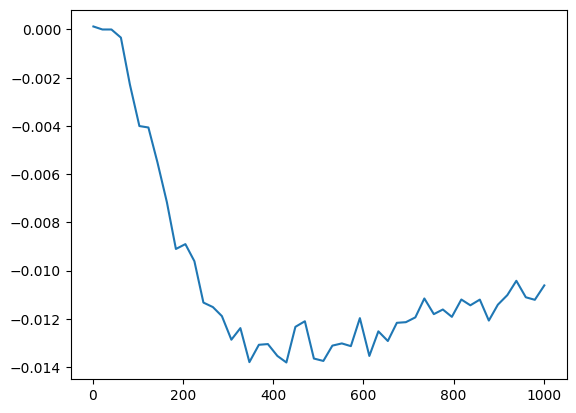

In [11]:
#Oppgave 3b
N_p = 40 * N_x 

Tp_vals = np.linspace(1, 1001, 50, dtype=int)

def run_one_cycle(Tp, rng):
    positions = np.empty(N_p, dtype=int)
    positions[:N_p//2] = 0
    positions[N_p//2:] = N_x

    j_list = []

    for t in range(2 * Tp):
        if t < Tp:
            Vtab = V2_tab
            p_m = np.full(N_p, 1/3)
            p_p = np.full(N_p, 1/3)
        else:
            Vtab = V1_tab
            p_m, _, p_p = step_probs(positions, Vtab, beta_k)

        r = rng.random(N_p)

        move_left  = (r <= p_m)
        move_right = (r >= 1 - p_p)

        positions = (positions - move_left.astype(int) + move_right.astype(int)) % P

        n_m = move_left.sum()
        n_p = move_right.sum()
        j_list.append((n_p - n_m) / N_p)

    return float(np.mean(j_list))

rng = np.random.default_rng(0)  

Javg_list = []
for T_p in Tp_vals:
    Javg = run_one_cycle(T_p, rng)
    Javg_list.append(Javg)
Javg_values = np.array(Javg_list)

plt.figure()
plt.plot(Tp_vals, Javg_values)
plt.show()


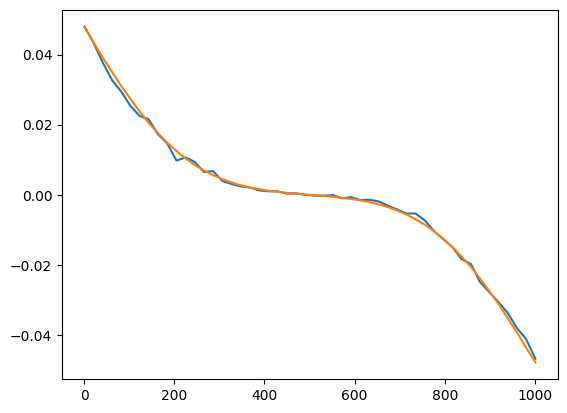

In [12]:
#Oppgave 3c

alpha_arr = np.arange(0.01, 1.0, 0.02)
T_p = 500
N_p = 12 * N_x

rng = np.random.default_rng(0)  

def erfc(x):
    val, err = integrate.quad(lambda t: np.exp(-t**2), x, np.inf)
    return 2 / np.sqrt(np.pi) * val

def analytic_current_mean(alpha):
    x1 = (alpha * N_x / 2) * np.sqrt(3 / T_p)
    x2 = ((1 - alpha) * N_x / 2) * np.sqrt(3 / T_p)
    return N_x / (4 * T_p) * (erfc(x1) - erfc(x2))

def func_b():
    global V1_tab
    anal_alpha = []
    Javg_list = []
    for alpha in alpha_arr:
        anal_alpha.append(analytic_current_mean(alpha))

        V1_tab = V1_array(P, N_x, alpha, k)  # oppdater GLOBAL V1_tab
        Javg = run_one_cycle(T_p, rng)
        Javg_list.append(Javg)

    return np.array(anal_alpha), np.array(Javg_list)

anal_alpha, Javg_values = func_b()

plt.figure()
plt.plot(Tp_vals, Javg_values)
plt.plot(Tp_vals, anal_alpha)
plt.show()

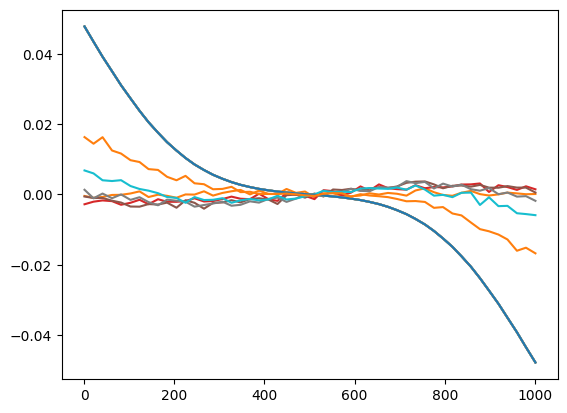

<Figure size 640x480 with 0 Axes>

In [13]:
# Oppgave 3d
beta_k_arr = np.array([0.01, 1, 2, 3, 5, 10])

def func_c():
    global beta_k
    a_lst = []
    J_lst = []
    for bk in beta_k_arr:
        beta_k = bk
        anal_alpha, Javg_values = func_b()
        a_lst.append(anal_alpha)
        J_lst.append(Javg_values)
    return np.array(a_lst), np.array(J_lst)

anal_alpha_arr, Javg_values_arr= func_c()

for i in range(6):
    plt.plot(Tp_vals,anal_alpha_arr[i])
    plt.plot(Tp_vals, Javg_values_arr[i])
        
plt.figure()
plt.show()

In [ ]:
#Oppgave 3e

alpha = 0.8
N_x = 10
T_p_vals = np.linspace(80,1501, 20, dtype = int)
